# Holdout Evaluation and Its Variance

This notebook illustrates the holdout protocol using a single `train_test_split`, and shows why the resulting test score depends on the particular split by repeating it with many random states.

## Import Required Libraries

Import numpy, matplotlib and scikit-learn tools for splitting, modelling and scoring.

In [1]:
# Import the required libraries.
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Define the course colour palette.
colors = ["#179E86", "#2580B7", "#9EBE5B",
          "#C03B26", "#44546A", "#F59B11"]
np.random.seed(42)

## Load the Dataset

Use the breast cancer dataset, a binary classification problem with 30 numeric features.

In [2]:
# Load the breast cancer dataset.
data = load_breast_cancer()
X, y = data.data, data.target
print(f"Samples: {X.shape[0]}, features: {X.shape[1]}.")
print(f"Class balance: {np.bincount(y)}.")

Samples: 569, features: 30.
Class balance: [212 357].


## A Single Holdout Split

Split the data once into training and test sets, fit a model and measure the test accuracy.

In [3]:
# Perform a single holdout split with a fixed seed.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Train a logistic regression model.
model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)

# Evaluate on the held-out test set.
single_score = accuracy_score(y_test, model.predict(X_test))
print(f"Single holdout accuracy: {single_score:.4f}.")

Single holdout accuracy: 0.9766.


## Why the Score Depends on the Split

Repeat the holdout with 50 different `random_state` values so each run uses a different train/test partition.

In [4]:
# Repeat the holdout with 50 different random states.
n_repeats = 50
scores = []
for state in range(n_repeats):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.3, random_state=state
    )
    clf = LogisticRegression(max_iter=5000)
    clf.fit(X_tr, y_tr)
    scores.append(accuracy_score(y_te, clf.predict(X_te)))

scores = np.array(scores)
print(f"Mean: {scores.mean():.4f}, std: {scores.std():.4f}.")
print(f"Min: {scores.min():.4f}, max: {scores.max():.4f}.")

Mean: 0.9497, std: 0.0169.
Min: 0.9123, max: 0.9883.


## Distribution of the Test Accuracy

Plot a histogram of the 50 test accuracies together with the mean and one-standard-deviation band to reveal the variance.

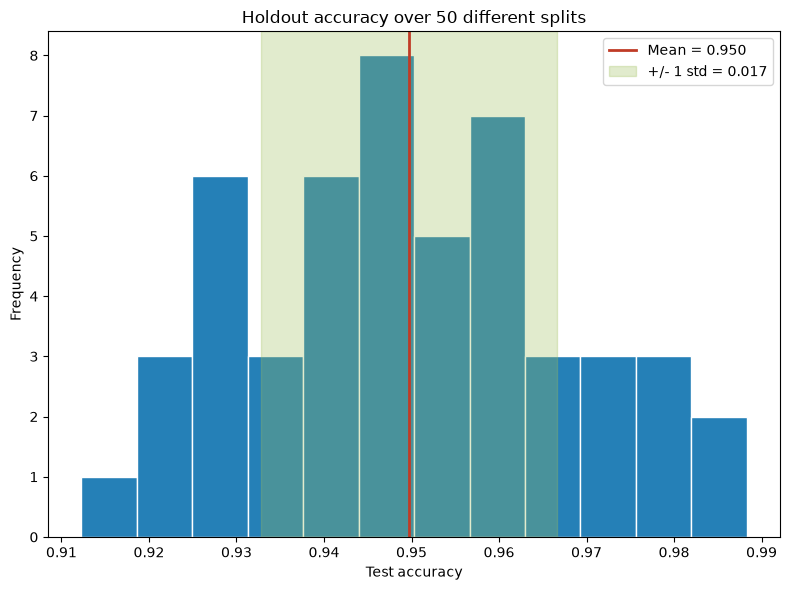

In [5]:
# Plot the distribution of test accuracies.
fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(scores, bins=12, color=colors[1], edgecolor="white")

# Mark the mean and the standard-deviation band.
mean, std = scores.mean(), scores.std()
ax.axvline(mean, color=colors[3], linewidth=2,
           label=f"Mean = {mean:.3f}")
ax.axvspan(mean - std, mean + std, color=colors[2], alpha=0.3,
           label=f"+/- 1 std = {std:.3f}")

ax.set_xlabel("Test accuracy")
ax.set_ylabel("Frequency")
ax.set_title("Holdout accuracy over 50 different splits")
ax.legend()
plt.tight_layout()
plt.show()

## Effect of the Test-Set Size

Smaller test sets give noisier estimates. Measure the spread of the accuracy for several `test_size` values.

In [6]:
# Measure the spread of accuracy for several test sizes.
sizes = [0.1, 0.2, 0.3, 0.4, 0.5]
means, stds = [], []
for size in sizes:
    reps = []
    for state in range(30):
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=size, random_state=state
        )
        clf = LogisticRegression(max_iter=5000).fit(X_tr, y_tr)
        reps.append(accuracy_score(y_te, clf.predict(X_te)))
    means.append(np.mean(reps))
    stds.append(np.std(reps))

for size, m, s in zip(sizes, means, stds):
    print(f"test_size={size}: mean={m:.4f}, std={s:.4f}.")

test_size=0.1: mean=0.9421, std=0.0318.
test_size=0.2: mean=0.9447, std=0.0167.
test_size=0.3: mean=0.9456, std=0.0130.
test_size=0.4: mean=0.9466, std=0.0146.
test_size=0.5: mean=0.9453, std=0.0116.


## Visualise the Spread Against Test Size

Plot the mean accuracy with error bars for each test-set fraction.

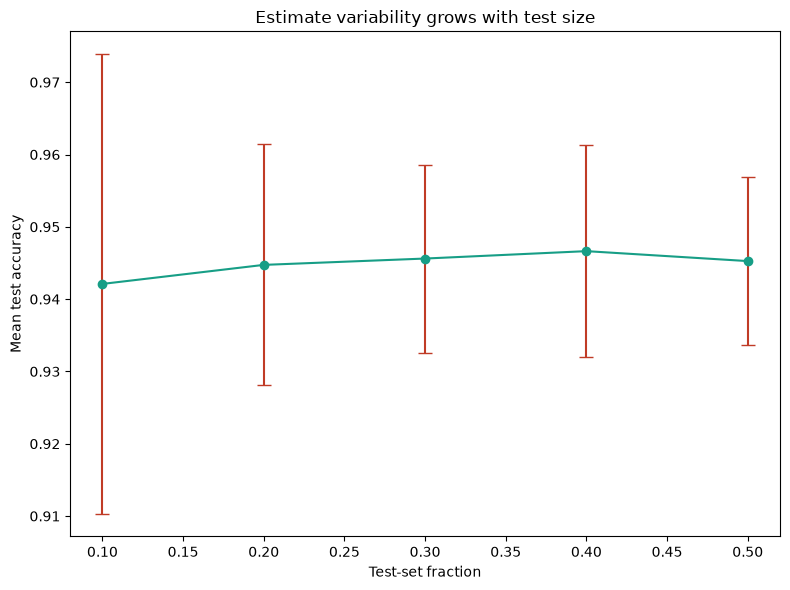

In [7]:
# Plot mean accuracy and variability versus test size.
fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(sizes, means, yerr=stds, marker="o",
            color=colors[0], ecolor=colors[3], capsize=5)
ax.set_xlabel("Test-set fraction")
ax.set_ylabel("Mean test accuracy")
ax.set_title("Estimate variability grows with test size")
plt.tight_layout()
plt.show()

## Summary

- **Holdout protocol**: a single `train_test_split` produces one point estimate of generalisation performance.
- **Split dependence**: the test score changes with the random partition, here spanning several accuracy points.
- **Variance source**: small or unlucky test sets yield noisy estimates, motivating resampling protocols.
- **Takeaway**: report the mean and spread over many splits, or use cross-validation for a more stable estimate.